<a href="https://colab.research.google.com/github/hadziqvinu/Visi-Komputer/blob/main/Jobsheet_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Praktikum D1 – Regresi dari Citra Sintetis (Prediksi Radius Lingkaran)

1) Setup & Generator Dataset

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models
# Generator 1 sample
def make_sample(img_size=64, min_r=5, max_r=20):
 r = np.random.randint(min_r, max_r + 1) # radius acak
 img = np.zeros((img_size, img_size), dtype=np.uint8)
 cx = np.random.randint(r, img_size - r) # center-x
 cy = np.random.randint(r, img_size - r) # center-y
 cv2.circle(img, (cx, cy), r, (255,), -1) # lingkaran putih terisi
 img = (img / 255.0).astype(np.float32)
 # 3-channel biar kompatibel CNN
 img3 = np.stack([img, img, img], axis=-1)
 return img3, float(r), (cx, cy)

2) “Tebak Apa?” — Tampilkan Contoh Gambar TANPA Label

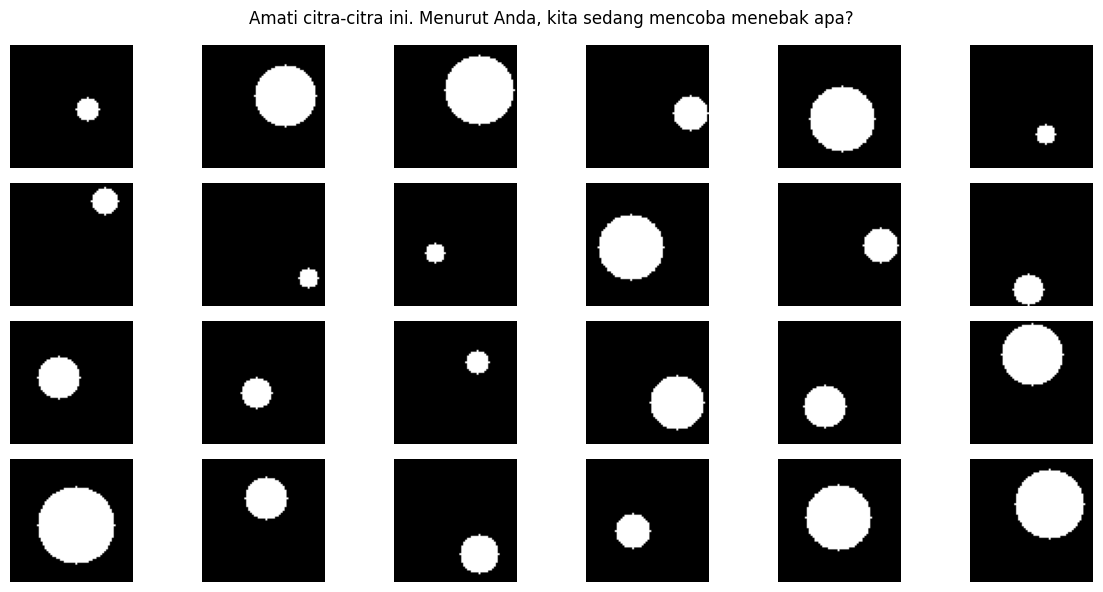

In [ ]:
# Buat 24 contoh untuk visualisasi
N_show = 24
samples = [make_sample() for _ in range(N_show)]
imgs = [s[0] for s in samples]
rads = [s[1] for s in samples]
centers = [s[2] for s in samples]
# Grid gambar tanpa label:
cols = 6
rows = N_show // cols
plt.figure(figsize=(12, 6))
for i in range(N_show):
 plt.subplot(rows, cols, i+1)
 plt.imshow(imgs[i].squeeze(), cmap='gray')
 plt.axis('off')
plt.suptitle("Amati citra-citra ini. Menurut Anda, kita sedang mencoba menebak apa?")
plt.tight_layout()
plt.show()


3) Buka Jawaban — Target yang Ingin Diprediksi


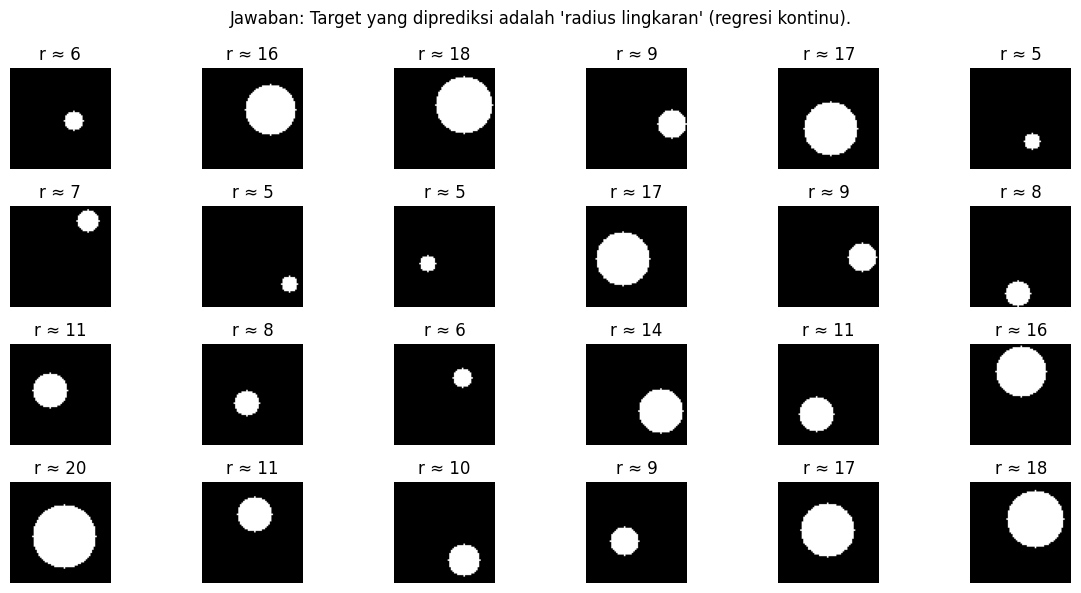

In [ ]:
# Tampilkan kembali, sekarang tampilkan radius (label) di judul tiap subplot
plt.figure(figsize=(12, 6))
for i in range(N_show):
 plt.subplot(rows, cols, i+1)
 plt.imshow(imgs[i].squeeze(), cmap='gray')
 plt.title(f"r ≈ {int(rads[i])}")
 plt.axis('off')
plt.suptitle("Jawaban: Target yang diprediksi adalah 'radius lingkaran' (regresi kontinu).")
plt.tight_layout()
plt.show()

4) (Opsional) Latih CNN Kecil untuk Memprediksi Radius dan 5) Tantangan Mini (Opsional untuk Mahasiswa)



19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
MAE=0.953 | RMSE=1.174 | R²=0.937
Radius 5-20 (baseline)       MAE=0.981 | RMSE=1.204 | R²=0.930
Radius 8-28                  MAE=0.796 | RMSE=0.970 | R²=0.975
Gaussian noise sigma=0.1     MAE=0.921 | RMSE=1.165 | R²=0.938
Gaussian noise sigma=0.3     MAE=0.882 | RMSE=1.109 | R²=0.938
Blur kernel 5                MAE=1.019 | RMSE=1.223 | R²=0.931


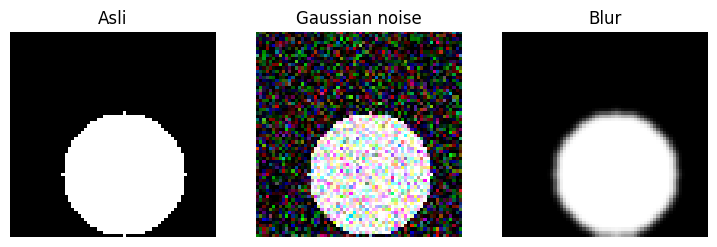

radius  MAE=0.309 | R²=0.992
cx      MAE=0.404 | R²=0.997
cy      MAE=0.378 | R²=0.998
Rata-rata  MAE=0.364 | R²=0.996


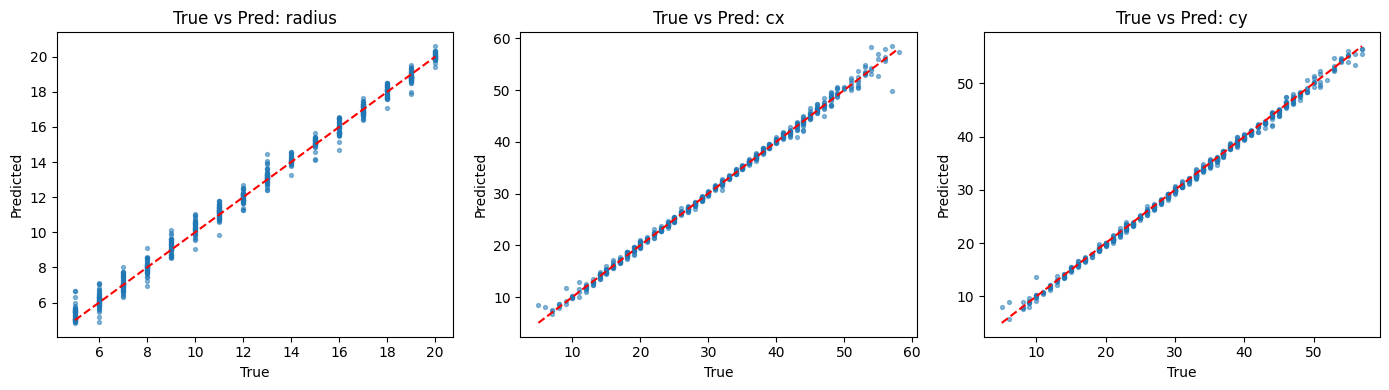

In [ ]:
# Siapkan dataset lebih besar untuk training
N = 3000
X, y, C = zip(*[make_sample() for _ in range(N)])
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
# Model CNN sederhana
model = models.Sequential([
 layers.Input((64,64,3)),
 layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
 layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
 layers.Conv2D(128, 3, activation='relu'),
layers.GlobalAveragePooling2D(),
 layers.Dense(64, activation='relu'),
 layers.Dense(1) # output regresi
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
history = model.fit(Xtr, ytr, validation_data=(Xte, yte),
 epochs=12, batch_size=64, verbose=0)
# Evaluasi
y_pred = model.predict(Xte).ravel()
mae = mean_absolute_error(yte, y_pred)
rmse = float(np.sqrt(np.mean((yte - y_pred)**2)))
r2 = r2_score(yte, y_pred)
print(f"MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}")

def run_experiment(min_r, max_r, N=3000, epochs=12, noise_fn=None, title=""):
    data = [make_sample(min_r=min_r, max_r=max_r) for _ in range(N)]
    X = np.array([d[0] for d in data], dtype=np.float32)
    y = np.array([d[1] for d in data], dtype=np.float32)

    if noise_fn is not None:
        X = np.array([noise_fn(x) for x in X], dtype=np.float32)

    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

    m = models.Sequential([
        layers.Input((64, 64, 3)),
        layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation='relu'),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation='relu'),
        layers.Dense(1)
    ])
    m.compile(optimizer='adam', loss='mse', metrics=['mae'])
    m.fit(Xtr, ytr, validation_data=(Xte, yte),
          epochs=epochs, batch_size=64, verbose=0)

    y_pred = m.predict(Xte, verbose=0).ravel()
    mae = mean_absolute_error(yte, y_pred)
    rmse = float(np.sqrt(np.mean((yte - y_pred) ** 2)))
    r2 = r2_score(yte, y_pred)
    print(f"{title:<28} MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}")
    return m, yte, y_pred

# Baseline vs rentang baru
run_experiment(5, 20, title="Radius 5-20 (baseline)")
run_experiment(8, 28, title="Radius 8-28")

def add_gaussian_noise(img, sigma=0.1):
    noisy = img + np.random.normal(0, sigma, img.shape).astype(np.float32)
    return np.clip(noisy, 0, 1)

def add_blur(img, k=5):
    return cv2.GaussianBlur(img, (k, k), 0)

run_experiment(5, 20, noise_fn=lambda x: add_gaussian_noise(x, 0.1),
               title="Gaussian noise sigma=0.1")
run_experiment(5, 20, noise_fn=lambda x: add_gaussian_noise(x, 0.3),
               title="Gaussian noise sigma=0.3")
run_experiment(5, 20, noise_fn=lambda x: add_blur(x, 5),
               title="Blur kernel 5")

# Contoh visual untuk laporan
img, r, _ = make_sample()
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, im, t in zip(ax,
                    [img, add_gaussian_noise(img, 0.3), add_blur(img, 5)],
                    ["Asli", "Gaussian noise", "Blur"]):
    a.imshow(im); a.set_title(t); a.axis('off')
plt.show()

N = 3000
data = [make_sample() for _ in range(N)]
X = np.array([d[0] for d in data], dtype=np.float32)
Y = np.array([[d[1], d[2][0], d[2][1]] for d in data], dtype=np.float32)  # [r, cx, cy]

Xtr, Xte, Ytr, Yte = train_test_split(X, Y, test_size=0.2, random_state=42)

SCALE = 64.0
model_mo = models.Sequential([
    layers.Input((64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(3)   # r, cx, cy
])
model_mo.compile(optimizer='adam', loss='mse', metrics=['mae'])
hist_mo = model_mo.fit(Xtr, Ytr / SCALE, validation_data=(Xte, Yte / SCALE),
                       epochs=20, batch_size=64, verbose=0)

Y_pred = model_mo.predict(Xte, verbose=0) * SCALE

names = ["radius", "cx", "cy"]
mae_each = mean_absolute_error(Yte, Y_pred, multioutput='raw_values')
r2_each = r2_score(Yte, Y_pred, multioutput='raw_values')
for n, m_, r_ in zip(names, mae_each, r2_each):
    print(f"{n:<7} MAE={m_:.3f} | R²={r_:.3f}")
print(f"Rata-rata  MAE={mae_each.mean():.3f} | R²={r2_each.mean():.3f}")

# Scatter True vs Predicted untuk tiap output
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for i, n in enumerate(names):
    ax[i].scatter(Yte[:, i], Y_pred[:, i], s=8, alpha=0.5)
    lims = [Yte[:, i].min(), Yte[:, i].max()]
    ax[i].plot(lims, lims, 'r--')
    ax[i].set_title(f"True vs Pred: {n}")
    ax[i].set_xlabel("True"); ax[i].set_ylabel("Predicted")
plt.tight_layout(); plt.show()

Praktikum D2 – Menebak Umur Manusia dari Foto Wajah (UTKFace)

Langkah 2 — Mengunggah kaggle.json ke Colab

In [ ]:
# Jalankan ini di awal notebook
from google.colab import files
files.upload() # pilih file kaggle.json dari komputer Anda


Saving kaggle.json to kaggle (3).json


{'kaggle (3).json': b'{"username":"hadziqv","key":"fb68d43aa56d119c3a53091f0151cf74"}'}

In [ ]:
import os, shutil
if os.path.exists("kaggle.json"):
 os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
 shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
 os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
 !pip -q install kaggle
 print("✅ Kaggle API siap digunakan.")
else:
 print(" kaggle.json belum ditemukan. Upload terlebih dahulu.")


✅ Kaggle API siap digunakan.


Langkah 3 — Mengunduh Dataset UTKFace dari Kaggle


In [ ]:
# Unduh dataset UTKFace (sekali saja)
!kaggle datasets download -d jangedoo/utkface-new -p /content -q
!unzip -q /content/utkface-new.zip -d /content/utk
print("✅ Dataset UTKFace berhasil diekstrak.")

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
replace /content/utk/UTKFace/100_0_0_20170112213500903.jpg.chip.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: ✅ Dataset UTKFace berhasil diekstrak.


Langkah 4 — Menampilkan Contoh Gambar Dataset


Total gambar ditemukan: 23708


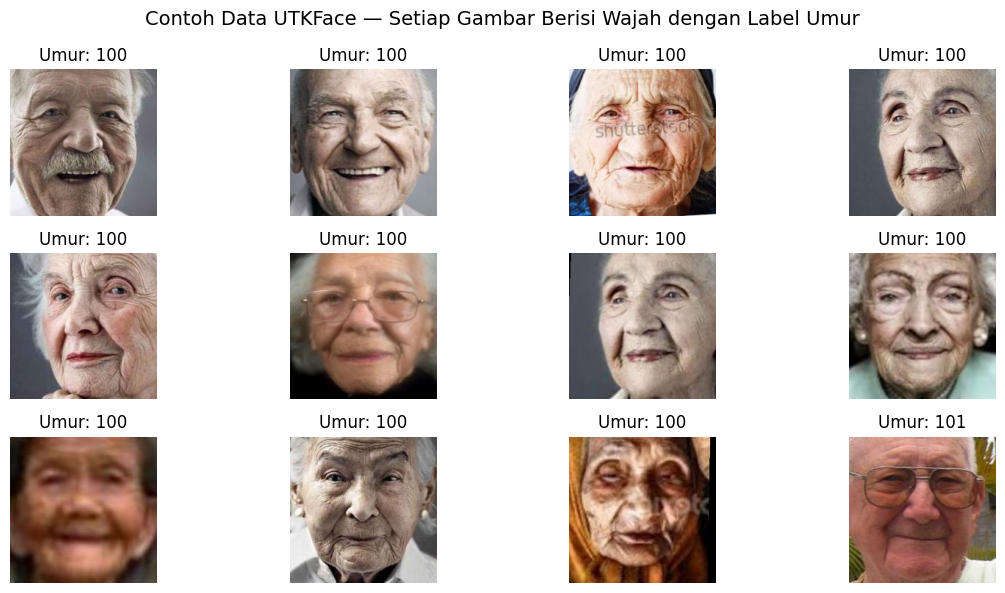

In [ ]:
import matplotlib.pyplot as plt
import os, glob
from PIL import Image
# Ambil 12 gambar acak dari dataset
files = glob.glob("/content/utk/UTKFace/*.jpg")
files = sorted(files)
print(f"Total gambar ditemukan: {len(files)}")
plt.figure(figsize=(12, 6))
for i, f in enumerate(files[:12]):
 # Ambil umur dari nama file
 age = int(os.path.basename(f).split("_")[0])
 img = Image.open(f)
 plt.subplot(3, 4, i + 1)
 plt.imshow(img)
 plt.title(f"Umur: {age}")
 plt.axis("off")
plt.suptitle("Contoh Data UTKFace — Setiap Gambar Berisi Wajah dengan Label Umur", fontsize=14)
plt.tight_layout()
plt.show()


Langkah 5 — Siapkan Dataset untuk Model


In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split
def parse_age_from_name(fp):
 return int(os.path.basename(fp).split('_')[0])
ages = np.array([parse_age_from_name(f) for f in files], dtype=np.float32)
train_files, test_files, y_train, y_test = train_test_split(
 files, ages, test_size=0.2, random_state=42
)
IMG_SIZE = 160
def load_img(fp, label):
 img = tf.io.read_file(fp)
 img = tf.image.decode_jpeg(img, channels=3)
 img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
 return img / 255.0, label
train_ds = tf.data.Dataset.from_tensor_slices((train_files,
y_train)).map(load_img).batch(64)
test_ds = tf.data.Dataset.from_tensor_slices((test_files,
y_test)).map(load_img).batch(64)
print("✅ Dataset siap dilatih.")

✅ Dataset siap dilatih.


Langkah 6 — Membangun Model dengan Transfer Learning

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
# Gunakan GPU jika tersedia
print("Hardware:", "GPU" if tf.config.list_physical_devices('GPU') else
"CPU")
# Buat arsitektur model
base_model = tf.keras.applications.MobileNetV2(
 include_top=False,
 input_shape=(IMG_SIZE, IMG_SIZE, 3),
 weights='imagenet'
)
base_model.trainable = False # tahap awal: freeze backbone
# Tambahkan head regresi
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1)(x) # output tunggal: umur
model = tf.keras.Model(inputs, outputs)
# Kompilasi model
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
 loss='mse', metrics=['mae'])
model.summary()

Hardware: GPU
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Langkah 7 — Melatih Model (Tahap 1 – Frozen)

Epoch 1/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 34s 76ms/step - loss: 211.7920 - mae: 10.8608 - val_loss: 154.9272 - val_mae: 9.4456 - learning_rate: 0.0010
Epoch 2/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - loss: 149.7554 - mae: 9.1428 - val_loss: 143.9603 - val_mae: 9.0036 - learning_rate: 0.0010
Epoch 3/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - loss: 143.2490 - mae: 8.8654 - val_loss: 140.8855 - val_mae: 8.8400 - learning_rate: 0.0010
Epoch 4/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - loss: 137.9774 - mae: 8.6784 - val_loss: 138.7653 - val_mae: 8.7729 - learning_rate: 0.0010
Epoch 5/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - loss: 135.1566 - mae: 8.5674 - val_loss: 134.8217 - val_mae: 8.5789 - learning_rate: 0.0010
Epoch 6/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 39ms/step - loss: 131.4233 - mae: 8.4415 - val_loss: 133.4859 - val_mae: 8.5465 - learning_rate: 0.0010
Epoch 7/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - loss: 129.2947 - mae: 8.3730 - val_loss: 131.1110 - val

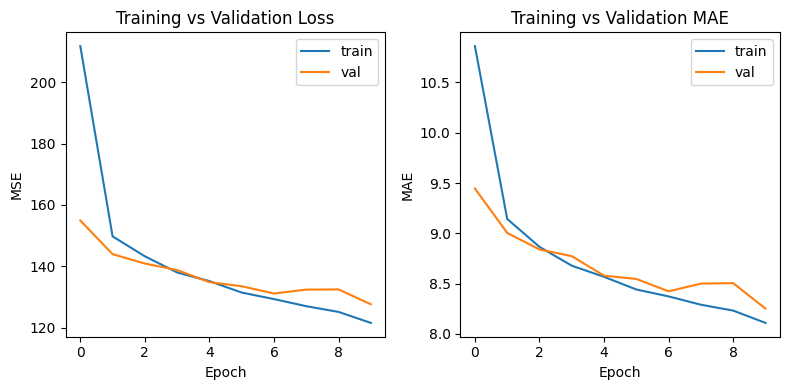

In [ ]:
# Callback untuk pelatihan yang lebih stabil
cb = [
 tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True,
monitor='val_loss'),
 tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5, monitor='val_loss')
]
history = model.fit(
 train_ds,
 validation_data=test_ds,
 epochs=10,
 callbacks=cb,
 verbose=1
)
# Visualisasi perubahan loss dan MAE selama pelatihan:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Training vs Validation Loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='train')
plt.plot(history.history['val_mae'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()
plt.tight_layout()
plt.show()


Langkah 8 — Fine-tuning Backbone (Tahap 2)


Epoch 1/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 58s 101ms/step - loss: 145.9847 - mae: 8.9096 - val_loss: 140.9357 - val_mae: 9.1278 - learning_rate: 1.0000e-04
Epoch 2/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - loss: 70.8558 - mae: 6.3343 - val_loss: 116.6830 - val_mae: 8.2379 - learning_rate: 1.0000e-04
Epoch 3/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - loss: 48.5123 - mae: 5.2976 - val_loss: 108.8523 - val_mae: 7.7755 - learning_rate: 1.0000e-04
Epoch 4/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - loss: 36.0105 - mae: 4.5721 - val_loss: 101.2591 - val_mae: 7.3573 - learning_rate: 1.0000e-04
Epoch 5/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 18s 62ms/step - loss: 29.1587 - mae: 4.1276 - val_loss: 106.7192 - val_mae: 7.4133 - learning_rate: 1.0000e-04


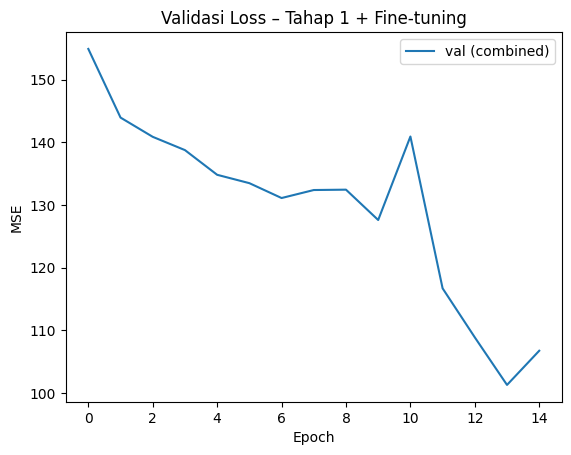

In [ ]:
# Aktifkan kembali sebagian layer terakhir untuk fine-tuning
base_model.trainable = True
for layer in base_model.layers[:-30]:
  layer.trainable = False # beku sebagian besar layer
# Recompile dengan learning rate lebih kecil
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
 loss='mse', metrics=['mae'])
history_ft = model.fit(
 train_ds,
 validation_data=test_ds,
 epochs=5,
 callbacks=cb,
 verbose=1
)
# Visualisasi gabungan training dan fine-tuning:
plt.plot(history.history['val_loss'] + history_ft.history['val_loss'],
label='val (combined)')
plt.title("Validasi Loss – Tahap 1 + Fine-tuning")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.legend(); plt.show()


Langkah 9 — Evaluasi Akhir (MAE, RMSE, R²)

MAE = 7.36 tahun
RMSE = 10.06 tahun
R² = 0.745


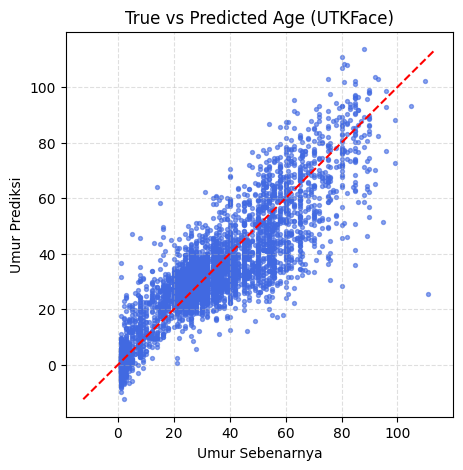

In [ ]:
from math import sqrt
y_pred = np.concatenate([model.predict(batch[0], verbose=0).ravel() for
batch in test_ds])
mae = mean_absolute_error(y_test, y_pred)
rmse = sqrt(np.mean((y_test - y_pred)**2))
r2 = r2_score(y_test, y_pred)
print(f"MAE = {mae:.2f} tahun")
print(f"RMSE = {rmse:.2f} tahun")
print(f"R² = {r2:.3f}")
# Plot “umur sebenarnya vs umur prediksi”:
plt.figure(figsize=(5,5))
plt.scatter(y_test, y_pred, s=8, alpha=0.6, color='royalblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("Umur Sebenarnya")
plt.ylabel("Umur Prediksi")
plt.title("True vs Predicted Age (UTKFace)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Langkah 10 — Melihat Contoh Prediksi Nyata

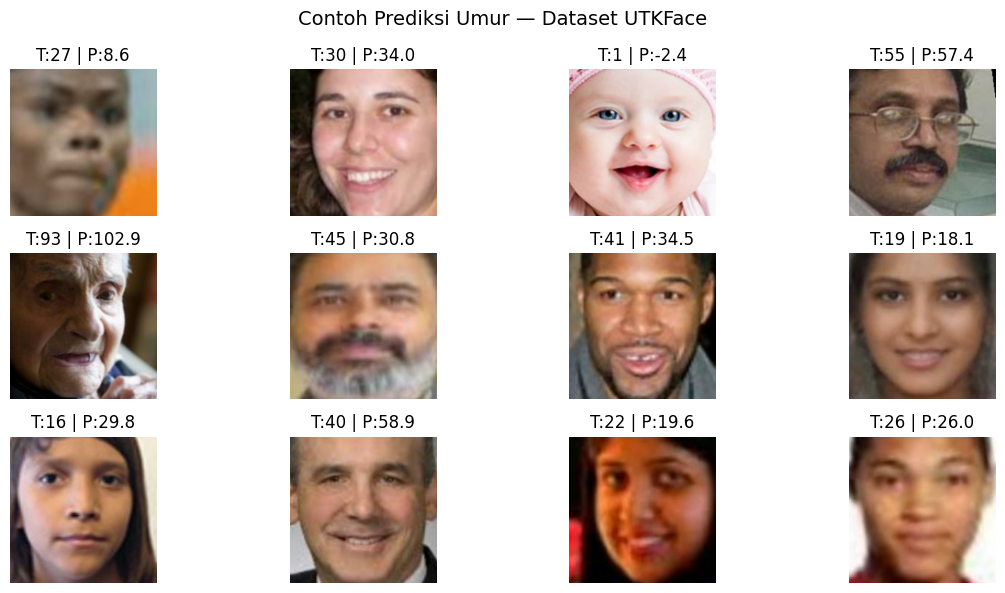

In [ ]:
import random
sample_paths = random.sample(test_files, 12)
plt.figure(figsize=(12,6))
for i, path in enumerate(sample_paths):
 img = tf.io.read_file(path)
 img = tf.image.decode_jpeg(img, channels=3)
 img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))/255.0
 true_age = int(os.path.basename(path).split('_')[0])
 pred_age = model.predict(tf.expand_dims(img, 0), verbose=0).ravel()[0]
 plt.subplot(3,4,i+1)
 plt.imshow(img.numpy())
 plt.title(f"T:{true_age} | P:{pred_age:.1f}")
 plt.axis('off')
plt.suptitle("Contoh Prediksi Umur — Dataset UTKFace", fontsize=14)
plt.tight_layout()
plt.show()

Tantangan Mini (Opsional)

In [ ]:
import numpy as np, os, math, random
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error

def build_model(augment=False):
    base = tf.keras.applications.MobileNetV2(
        include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3), weights='imagenet')
    base.trainable = False
    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = inputs
    if augment:  # hanya aktif saat training
        x = tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomZoom(0.1),
            layers.RandomContrast(0.2),
            layers.RandomBrightness(0.2, value_range=(0, 1)),
        ])(x)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(1)(x)
    return tf.keras.Model(inputs, outputs), base

def new_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss'),
        tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5, monitor='val_loss'),
    ]

def train_two_stage(model, base, opt1, opt2, ep1=10, ep2=5, use_plateau=True):
    cbs = new_callbacks() if use_plateau else [new_callbacks()[0]]
    model.compile(optimizer=opt1, loss='mse', metrics=['mae'])
    h1 = model.fit(train_ds, validation_data=test_ds, epochs=ep1, callbacks=cbs, verbose=1)

    base.trainable = True
    for l in base.layers[:-30]:
        l.trainable = False
    cbs = new_callbacks() if use_plateau else [new_callbacks()[0]]
    model.compile(optimizer=opt2, loss='mse', metrics=['mae'])
    h2 = model.fit(train_ds, validation_data=test_ds, epochs=ep2, callbacks=cbs, verbose=1)
    return h1.history['val_loss'] + h2.history['val_loss']

def predict_all(model):
    return np.concatenate([model.predict(b[0], verbose=0).ravel() for b in test_ds])

results = {}   # simpan semua hasil untuk tabel akhir

In [ ]:
# Tanpa augmentasi (baseline)
m0, b0 = build_model(augment=False)
vl0 = train_two_stage(m0, b0, tf.keras.optimizers.Adam(1e-3), tf.keras.optimizers.Adam(1e-4))
p0 = predict_all(m0)
results["Baseline (tanpa aug)"] = mean_absolute_error(y_test, p0)

# Dengan augmentasi
m1, b1 = build_model(augment=True)
vl1 = train_two_stage(m1, b1, tf.keras.optimizers.Adam(1e-3), tf.keras.optimizers.Adam(1e-4))
p1 = predict_all(m1)
results["Augmentasi"] = mean_absolute_error(y_test, p1)

print(f"MAE baseline  : {results['Baseline (tanpa aug)']:.2f} tahun")
print(f"MAE augmentasi: {results['Augmentasi']:.2f} tahun")

Epoch 1/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - loss: 219.5715 - mae: 11.0177 - val_loss: 158.3169 - val_mae: 9.5690 - learning_rate: 0.0010
Epoch 2/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 15s 51ms/step - loss: 152.0910 - mae: 9.1816 - val_loss: 146.9616 - val_mae: 9.1190 - learning_rate: 0.0010
Epoch 3/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - loss: 144.3525 - mae: 8.8666 - val_loss: 142.3124 - val_mae: 8.9156 - learning_rate: 0.0010
Epoch 4/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 16s 54ms/step - loss: 139.0033 - mae: 8.7011 - val_loss: 139.6261 - val_mae: 8.7772 - learning_rate: 0.0010
Epoch 5/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 52ms/step - loss: 137.4287 - mae: 8.6311 - val_loss: 139.4561 - val_mae: 8.7868 - learning_rate: 0.0010
Epoch 6/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - loss: 134.3185 - mae: 8.5322 - val_loss: 136.0704 - val_mae: 8.6141 - learning_rate: 0.0010
Epoch 7/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - loss: 132.3651 - mae: 8.4565 - val_loss: 135.7273 - val

Epoch 1/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 29s 79ms/step - loss: 231.6696 - mae: 11.3719 - val_loss: 166.9197 - val_mae: 9.9323
Epoch 2/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 22s 75ms/step - loss: 157.6891 - mae: 9.3878 - val_loss: 157.1240 - val_mae: 9.5745
Epoch 3/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 22s 75ms/step - loss: 148.8314 - mae: 9.0643 - val_loss: 150.7420 - val_mae: 9.3139
Epoch 4/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 22s 74ms/step - loss: 144.3978 - mae: 8.8764 - val_loss: 142.0028 - val_mae: 8.9060
Epoch 5/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 22s 75ms/step - loss: 141.2564 - mae: 8.7895 - val_loss: 138.6796 - val_mae: 8.7460
Epoch 6/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 22s 75ms/step - loss: 139.0282 - mae: 8.7074 - val_loss: 137.2148 - val_mae: 8.6715
Epoch 7/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 22s 74ms/step - loss: 138.0907 - mae: 8.6484 - val_loss: 138.1891 - val_mae: 8.7310
Epoch 8/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 41s 75ms/step - loss: 136.7451 - mae: 8.6161 - val_loss: 135.7189 - val_mae: 8.5779
Epoch 9

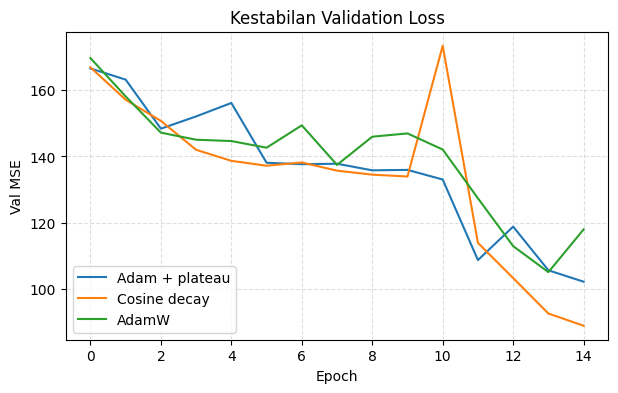

Adam + plateau   std perubahan val_loss = 9.19
Cosine decay     std perubahan val_loss = 19.17
AdamW            std perubahan val_loss = 8.49


In [ ]:
steps_per_epoch = math.ceil(len(train_files) / 64)

# (a) Cosine decay
cos1 = tf.keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=10 * steps_per_epoch)
cos2 = tf.keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=5 * steps_per_epoch)
m2, b2 = build_model(augment=True)
vl2 = train_two_stage(m2, b2, tf.keras.optimizers.Adam(cos1), tf.keras.optimizers.Adam(cos2),
                      use_plateau=False)   # ReduceLROnPlateau tidak dipakai bersama schedule
p2 = predict_all(m2)
results["Cosine decay"] = mean_absolute_error(y_test, p2)

# (b) AdamW
m3, b3 = build_model(augment=True)
vl3 = train_two_stage(m3, b3,
                      tf.keras.optimizers.AdamW(1e-3, weight_decay=1e-4),
                      tf.keras.optimizers.AdamW(1e-4, weight_decay=1e-4))
p3 = predict_all(m3)
results["AdamW"] = mean_absolute_error(y_test, p3)

# Kestabilan: bandingkan kurva val_loss dan fluktuasinya
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
for name, vl in [("Adam + plateau", vl1), ("Cosine decay", vl2), ("AdamW", vl3)]:
    plt.plot(vl, label=name)
plt.xlabel("Epoch"); plt.ylabel("Val MSE"); plt.title("Kestabilan Validation Loss")
plt.legend(); plt.grid(True, linestyle='--', alpha=0.4); plt.show()

for name, vl in [("Adam + plateau", vl1), ("Cosine decay", vl2), ("AdamW", vl3)]:
    print(f"{name:<16} std perubahan val_loss = {np.std(np.diff(vl)):.2f}")

In [ ]:
p_best = p1   # ganti ke p2 / p3 bila lebih baik
y_true = np.array(y_test)

bins   = [0, 10, 20, 30, 40, 50, 60, 70, 80, 200]
labels = ["0-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61-70", "71-80", "81+"]
group  = np.digitize(y_true, bins[1:-1], right=True)

print(f"{'Kelompok':<10}{'Jumlah':>8}{'MAE':>8}{'Bias':>8}")
worst = (None, 0)
for g, lab in enumerate(labels):
    idx = group == g
    if idx.sum() == 0:
        continue
    mae_g  = mean_absolute_error(y_true[idx], p_best[idx])
    bias_g = np.mean(p_best[idx] - y_true[idx])   # + = diprediksi lebih tua
    print(f"{lab:<10}{idx.sum():>8}{mae_g:>8.2f}{bias_g:>8.2f}")
    if mae_g > worst[1]:
        worst = (lab, mae_g)
print(f"\nError terbesar: kelompok {worst[0]} (MAE {worst[1]:.2f} tahun)")

Kelompok    Jumlah     MAE    Bias
0-10           627    4.99    4.39
11-20          319   10.91    9.90
21-30         1570    8.19    7.64
31-40          851    6.22    3.94
41-50          415    6.61    0.15
51-60          457    8.76   -0.82
61-70          259    9.85   -2.92
71-80          136   11.31   -4.05
81+            108   11.80   -5.44

Error terbesar: kelompok 81+ (MAE 11.80 tahun)


Model m2 tidak ditemukan. Menggunakan model baseline ('model') yang aktif di memori.
Mengatur resolusi gambar secara otomatis menjadi: (224, 224)


Saving wajah.jpeg to wajah (1).jpeg


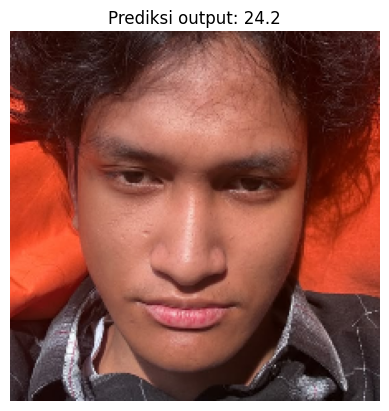

In [ ]:
from google.colab import files as colab_files   # alias agar tidak bentrok dengan variabel `files`
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Definisikan model terbaik hasil eksperimen dengan fallback aman
try:
    best_model = m2
    print("Menggunakan model terbaik hasil eksperimen (m2: Cosine Decay).")
except NameError:
    best_model = model
    print("Model m2 tidak ditemukan. Menggunakan model baseline ('model') yang aktif di memori.")

# Dapatkan target dimensi input model secara dinamis
try:
    target_size = best_model.input_shape[1:3] # Mengambil (tinggi, lebar)
    if target_size[0] is None or target_size[1] is None:
        target_size = (160, 160)
except Exception:
    target_size = (160, 160)

print(f"Mengatur resolusi gambar secara otomatis menjadi: {target_size}")

up = colab_files.upload()          # pilih foto wajah (jpg/png)
path = list(up.keys())[0]

# Opsional: crop wajah otomatis agar mirip format UTKFace
import cv2
bgr = cv2.imread(path)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
faces = cascade.detectMultiScale(gray, 1.1, 5)
if len(faces):
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
    pad = int(0.15 * w)
    x0, y0 = max(x - pad, 0), max(y - pad, 0)
    bgr = bgr[y0:y + h + pad, x0:x + w + pad]
else:
    print("Wajah tidak terdeteksi, memakai seluruh gambar.")

img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (target_size[1], target_size[0])).astype(np.float32) / 255.0

pred = best_model.predict(img[None, ...], verbose=0).ravel()[0]   # best_model = m1 / m2 / m3
plt.imshow(img); plt.axis('off')
plt.title(f"Prediksi output: {pred:.1f}")
plt.show()

Praktikum D3 — Menilai “Kepopuleran Hewan Peliharaan” dari Foto

Langkah 1 — Menyiapkan Kaggle API


In [ ]:
from google.colab import files
files.upload() # pilih kaggle.json dari komputer Anda
import os, shutil
if os.path.exists("kaggle.json"):
 os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
 shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
 os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
 !pip -q install kaggle
 print("✅ Kaggle API siap digunakan.")
else:
 print(" kaggle.json belum ditemukan. Upload terlebih dahulu.")

Saving kaggle.json to kaggle.json
✅ Kaggle API siap digunakan.


Langkah 2 — Mengunduh dan Mengekstrak Dataset

In [ ]:
# Unduh dataset Pawpularity (sekitar 800MB)
!kaggle competitions download -c petfinder-pawpularity-score -p /content -q
!unzip -q /content/petfinder-pawpularity-score.zip -d /content/paw
print("✅ Dataset Pawpularity berhasil diekstrak.")

✅ Dataset Pawpularity berhasil diekstrak.


Langkah 3 — Melihat Contoh Data

                                 Id  Subject Focus  Eyes  Face  Near  Action  \
0  0007de18844b0dbbb5e1f607da0606e0              0     1     1     1       0   
1  0009c66b9439883ba2750fb825e1d7db              0     1     1     0       0   
2  0013fd999caf9a3efe1352ca1b0d937e              0     1     1     1       0   
3  0018df346ac9c1d8413cfcc888ca8246              0     1     1     1       0   
4  001dc955e10590d3ca4673f034feeef2              0     0     0     1       0   

   Accessory  Group  Collage  Human  Occlusion  Info  Blur  Pawpularity  \
0          0      1        0      0          0     0     0           63   
1          0      0        0      0          0     0     0           42   
2          0      0        0      1          1     0     0           28   
3          0      0        0      0          0     0     0           15   
4          0      1        0      0          0     0     0           72   

                                                path  
0  /content/p

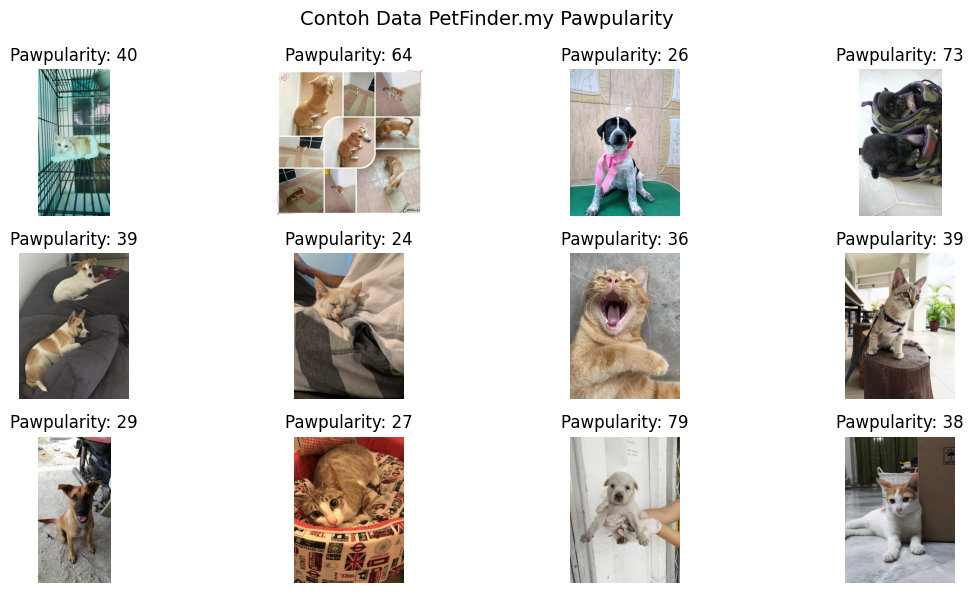

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from PIL import Image
# Muat CSV
df = pd.read_csv('/content/paw/train.csv')
df['path'] = df['Id'].apply(lambda x: f"/content/paw/train/{x}.jpg")
print(df.head())
# Tampilkan 12 contoh gambar
plt.figure(figsize=(12, 6))
for i, row in enumerate(df.sample(12, random_state=42).itertuples()):
 img = Image.open(row.path)
 plt.subplot(3, 4, i + 1)
 plt.imshow(img)
 plt.title(f"Pawpularity: {row.Pawpularity}")
 plt.axis('off')
plt.suptitle("Contoh Data PetFinder.my Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

Langkah 4 — Persiapan Dataset


In [ ]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
IMG_SIZE = 224
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)
def load_image(path, label):
 img = tf.io.read_file(path)
 img = tf.image.decode_jpeg(img, channels=3)
 img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
 img = tf.cast(img, tf.float32) / 255.0
 return img, tf.cast(label, tf.float32)
train_ds = tf.data.Dataset.from_tensor_slices((train_df['path'],
train_df['Pawpularity']))\
 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
 .shuffle(4096).batch(64).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((val_df['path'],
val_df['Pawpularity']))\
 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
 .batch(64).prefetch(tf.data.AUTOTUNE)
print(f"Dataset siap digunakan — {len(train_df)} untuk training, {len(val_df)} untuk validasi.")

Dataset siap digunakan — 7929 untuk training, 1983 untuk validasi.


Langkah 4 — Membangun Model (EfficientNetB0)


In [ ]:
from tensorflow.keras import layers, models
base = tf.keras.applications.EfficientNetB0(
 include_top=False,
 input_shape=(IMG_SIZE, IMG_SIZE, 3),
 weights='imagenet'
)
base.trainable = False # freeze sementara
inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs * 255.0)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation='relu')(x)
outputs = layers.Dense(1)(x)
model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Langkah 5 — Melatih Model


In [ ]:
cb = [
 tf.keras.callbacks.EarlyStopping(patience=3,
restore_best_weights=True),
 tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=10,
callbacks=cb, verbose=1)


Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 100s 442ms/step - loss: 591.1174 - mae: 17.7931 - val_loss: 473.9359 - val_mae: 16.1341 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 37s 200ms/step - loss: 420.5156 - mae: 15.1156 - val_loss: 428.2434 - val_mae: 15.4409 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 38s 180ms/step - loss: 390.2376 - mae: 14.6301 - val_loss: 406.7378 - val_mae: 14.9209 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 39s 224ms/step - loss: 376.6153 - mae: 14.4047 - val_loss: 396.6356 - val_mae: 14.3517 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 42s 226ms/step - loss: 362.0239 - mae: 14.1095 - val_loss: 386.7337 - val_mae: 14.7113 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 36s 188ms/step - loss: 355.2776 - mae: 14.0238 - val_loss: 371.4926 - val_mae: 14.2626 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 34s 186ms/step - loss: 349.5859 - mae: 13.8543 - val_

Langkah 6 — Melihat Proses Belajar

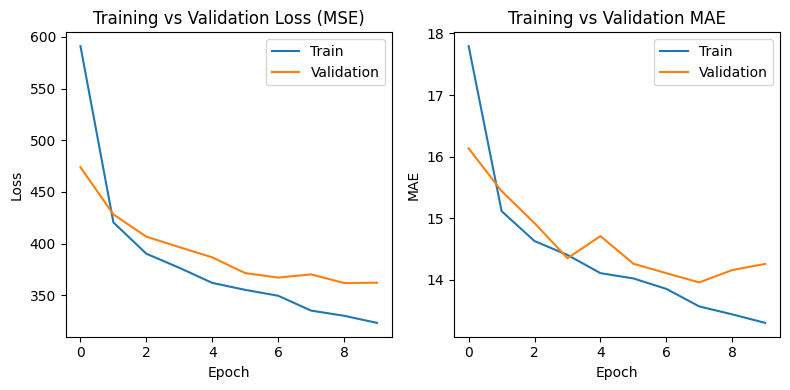

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Training vs Validation Loss (MSE)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='Train')
plt.plot(history.history['val_mae'], label='Validation')
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch"); plt.ylabel("MAE"); plt.legend()
plt.tight_layout()
plt.show()

Langkah 7 — Evaluasi Model


MAE = 14.16
RMSE = 19.02
R² = 0.181


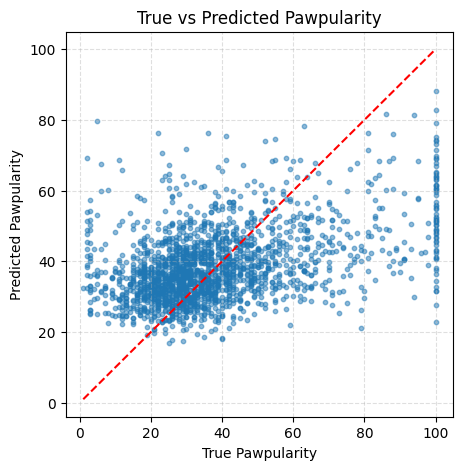

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
from math import sqrt
y_true = val_df['Pawpularity'].values.astype(np.float32)
y_pred = np.concatenate([model.predict(batch[0], verbose=0).ravel() for
batch in val_ds])
mae = mean_absolute_error(y_true, y_pred)
rmse = sqrt(np.mean((y_true - y_pred)**2))
r2 = r2_score(y_true, y_pred)
print(f"MAE = {mae:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"R² = {r2:.3f}")
# Plot hasil prediksi vs nilai sebenarnya:
plt.figure(figsize=(5,5))
plt.scatter(y_true, y_pred, s=10, alpha=0.5)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("True Pawpularity")
plt.ylabel("Predicted Pawpularity")
plt.title("True vs Predicted Pawpularity")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Langkah 8 — Melihat Contoh Prediksi

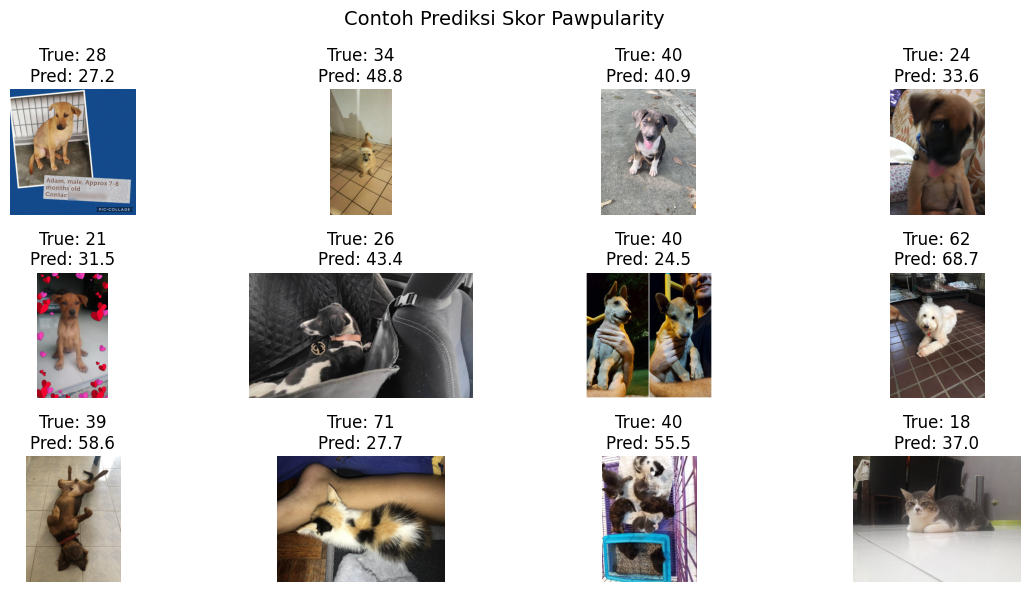

In [ ]:
import random
from PIL import Image
sample_rows = val_df.sample(12, random_state=1)
plt.figure(figsize=(12,6))
for i, row in enumerate(sample_rows.itertuples()):
 img = Image.open(row.path)
 pred = model.predict(tf.expand_dims(load_image(row.path,
row.Pawpularity)[0], 0), verbose=0).ravel()[0]
 plt.subplot(3,4,i+1)
 plt.imshow(img)
 plt.title(f"True: {row.Pawpularity}\nPred: {pred:.1f}")
 plt.axis('off')
plt.suptitle("Contoh Prediksi Skor Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

Tantangan Mini

In [ ]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, r2_score
from math import sqrt

y_val = val_df['Pawpularity'].values.astype(np.float32)
results = {}

def build_model(backbone="b0", augment=False):
    if backbone == "b0":
        base = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                                    input_shape=(IMG_SIZE, IMG_SIZE, 3))
        prep = tf.keras.applications.efficientnet.preprocess_input
    elif backbone == "b3":
        base = tf.keras.applications.EfficientNetB3(include_top=False, weights='imagenet',
                                                    input_shape=(IMG_SIZE, IMG_SIZE, 3))
        prep = tf.keras.applications.efficientnet.preprocess_input
    elif backbone == "resnet50":
        base = tf.keras.applications.ResNet50(include_top=False, weights='imagenet',
                                              input_shape=(IMG_SIZE, IMG_SIZE, 3))
        prep = tf.keras.applications.resnet50.preprocess_input
    base.trainable = False

    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = inputs
    if augment:  # hanya aktif saat training
        x = tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.RandomZoom(0.1),
            layers.RandomContrast(0.2),
            layers.RandomBrightness(0.2, value_range=(0, 1)),
        ])(x)
    x = prep(x * 255.0)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    outputs = layers.Dense(1)(x)
    return tf.keras.Model(inputs, outputs)

def new_cb():
    return [tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)]

def train_eval(model, name, data_val=None, data_train=None, epochs=10):
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    model.fit(data_train or train_ds, validation_data=data_val or val_ds,
              epochs=epochs, callbacks=new_cb(), verbose=1)
    pred = model.predict(data_val or val_ds, verbose=0).ravel()
    mae = mean_absolute_error(y_val, pred)
    rmse = sqrt(np.mean((y_val - pred) ** 2))
    r2 = r2_score(y_val, pred)
    results[name] = (mae, rmse, r2)
    print(f"{name}: MAE={mae:.2f} | RMSE={rmse:.2f} | R2={r2:.3f}")
    return pred

In [ ]:
m_base = build_model("b0", augment=False)
p_base = train_eval(m_base, "B0 baseline")

m_aug = build_model("b0", augment=True)
p_aug = train_eval(m_aug, "B0 + augmentasi")

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 89s 422ms/step - loss: 606.4219 - mae: 18.0095 - val_loss: 479.5578 - val_mae: 16.1455 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 37s 196ms/step - loss: 419.4203 - mae: 15.0717 - val_loss: 429.6421 - val_mae: 15.3886 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 41s 232ms/step - loss: 395.4537 - mae: 14.7032 - val_loss: 405.9783 - val_mae: 14.8988 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 39s 208ms/step - loss: 378.3129 - mae: 14.4145 - val_loss: 392.5280 - val_mae: 14.4950 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 37s 200ms/step - loss: 365.9453 - mae: 14.2114 - val_loss: 381.1809 - val_mae: 14.4884 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 39s 212ms/step - loss: 354.8731 - mae: 13.9480 - val_loss: 375.5850 - val_mae: 14.5453 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 40s 204ms/step - loss: 347.2501 - mae: 13.8636 - val_l

In [ ]:
m_b3 = build_model("b3", augment=True)
p_b3 = train_eval(m_b3, "EfficientNetB3 + aug")

m_r50 = build_model("resnet50", augment=True)
p_r50 = train_eval(m_r50, "ResNet50 + aug")

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 75s 384ms/step - loss: 663.8400 - mae: 18.9316 - val_loss: 518.7456 - val_mae: 16.3333 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 54s 335ms/step - loss: 454.5983 - mae: 15.7790 - val_loss: 447.2293 - val_mae: 15.2551 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 54s 339ms/step - loss: 410.1724 - mae: 15.0880 - val_loss: 406.7746 - val_mae: 14.8097 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 54s 340ms/step - loss: 392.6986 - mae: 14.7727 - val_loss: 391.5739 - val_mae: 14.6129 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 54s 343ms/step - loss: 371.5931 - mae: 14.3575 - val_loss: 376.0680 - val_mae: 14.3203 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 54s 344ms/step - loss: 362.6286 - mae: 14.2289 - val_loss: 374.1654 - val_mae: 14.0973 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 57s

Spesies     Jumlah  Skor asli  Skor pred     MAE    Bias
anjing        1103      41.09      37.77   15.77   -3.32
kucing         707      34.26      32.94   11.31   -1.31
lainnya        173      34.20      32.13   11.90   -2.07


/tmp/ipykernel_1793/3083728863.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([y_val[species == s] for s in ["anjing", "kucing"]], labels=["anjing", "kucing"])


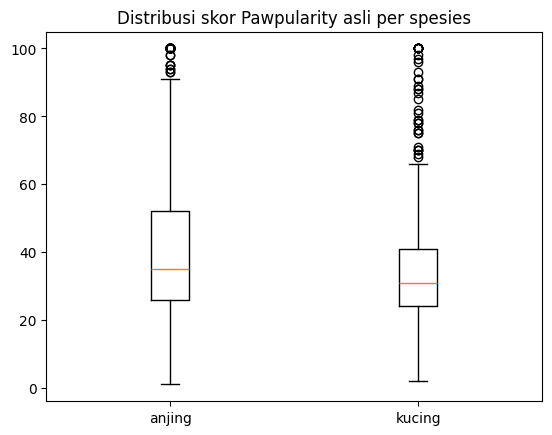

In [ ]:
clf = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=True,
                                        input_shape=(224, 224, 3))
imgs_only = val_ds.map(lambda x, y: tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0))
probs = clf.predict(imgs_only, verbose=0)

dog_p = probs[:, 151:269].sum(axis=1)
cat_p = probs[:, 281:286].sum(axis=1)
species = np.where((dog_p < 0.2) & (cat_p < 0.2), "lainnya",
                   np.where(dog_p > cat_p, "anjing", "kucing"))

p_best = p_aug   # ganti ke prediksi model terbaik
print(f"{'Spesies':<10}{'Jumlah':>8}{'Skor asli':>11}{'Skor pred':>11}{'MAE':>8}{'Bias':>8}")
for s in ["anjing", "kucing", "lainnya"]:
    idx = species == s
    if idx.sum() == 0:
        continue
    print(f"{s:<10}{idx.sum():>8}{y_val[idx].mean():>11.2f}{p_best[idx].mean():>11.2f}"
          f"{mean_absolute_error(y_val[idx], p_best[idx]):>8.2f}"
          f"{np.mean(p_best[idx] - y_val[idx]):>8.2f}")

plt.boxplot([y_val[species == s] for s in ["anjing", "kucing"]], labels=["anjing", "kucing"])
plt.title("Distribusi skor Pawpularity asli per spesies"); plt.show()